In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, acf, pacf
import statsmodels.tsa.api as smt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

# **`Part 1: Data Preparation and Exploration`**




**1.	Data Loading: Load the exchange_rate.csv dataset and parse the date column appropriately.**


In [2]:
#load the data
#parse the data column and make it as index
exchange = pd.read_csv('exchange_rate.csv', parse_dates = True, index_col = 'date')

In [3]:
exchange.shape

(7588, 1)

In [4]:
exchange.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7588 entries, 01-01-1990 00:00 to 10-10-2010 00:00
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Ex_rate  7588 non-null   float64
dtypes: float64(1)
memory usage: 118.6+ KB


In [5]:
exchange.head()

,Ex_rate
date,
01-01-1990 00:00,0.7855
02-01-1990 00:00,0.7818
03-01-1990 00:00,0.7867
04-01-1990 00:00,0.7860
05-01-1990 00:00,0.7849


**2.	Initial Exploration:  Plot the time series for currency to understand their trends, seasonality, and any anomalies.**


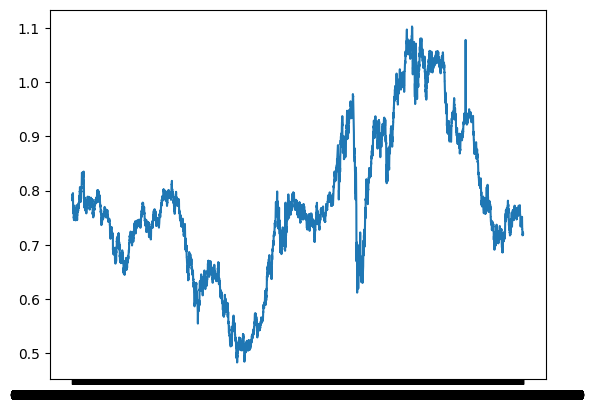

In [6]:
plt.plot(exchange)


<Axes: xlabel='date'>

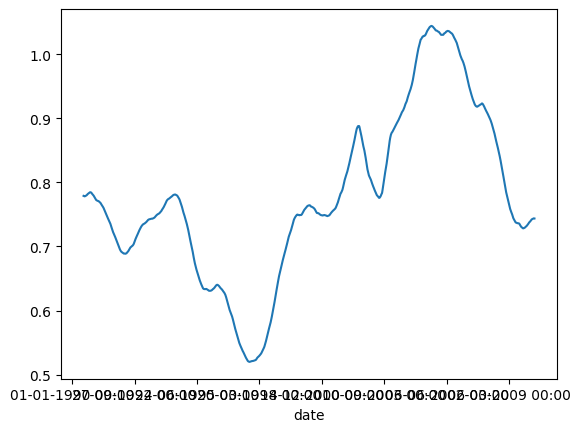

In [7]:
#seasonal decompose to get separate plots for trend, seasonal, resid
#used period = 365 for 365 days
result = seasonal_decompose(exchange['Ex_rate'], model = 'Additive', period=365)
result.trend.plot()

<Axes: xlabel='date'>

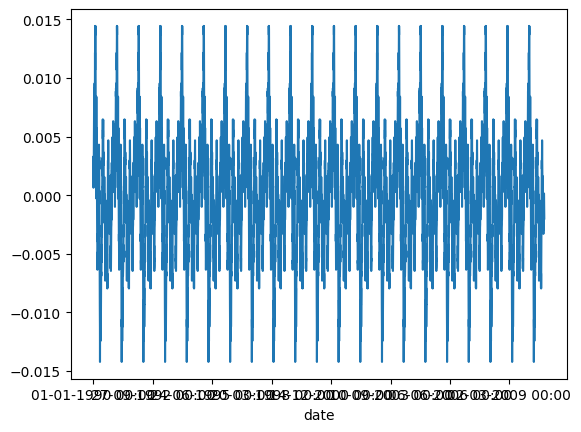

In [8]:
result.seasonal.plot()

<Axes: xlabel='date'>

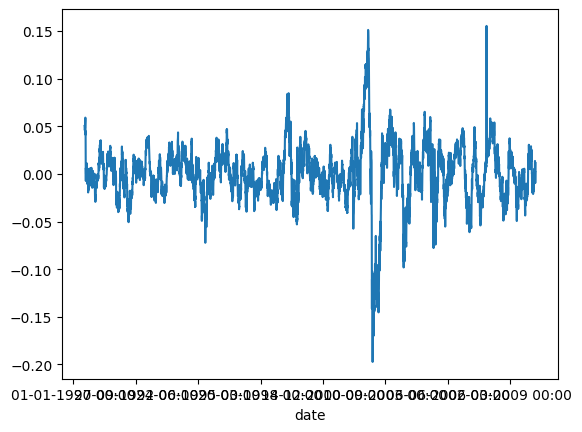

In [9]:
result.resid.plot()

**3.	Data Preprocessing: Handle any missing values or anomalies identified during the exploration phase.**

In [10]:
#checking whether data is staionary or not
def test_stationarity(timeseries):

  #calculating rollimg mean and rollimg standarad deviation
  rollmean = timeseries.rolling(window = 12).mean()
  rollstd = timeseries.rolling(window = 12).std()

  original = plt.plot(timeseries, color = 'red', label = 'Original')
  mean = plt.plot(rollmean, color = 'blue', label = 'Rolling Mean')
  std = plt.plot(rollstd, color = 'green', label = 'Rolling Std')
  plt.legend(loc = 'best')
  plt.title('Rolling Mean and Standard Deviation')
  plt.show()

  print('Results of Dickey-Fuller Test: \n')
  df_test = adfuller(timeseries)
  my_output = pd.Series(df_test[0:4], index = ['Test Statistic', 'p-value', '#Lags Used', 'Number of Observations Used'])
  for i, j in df_test[4].items():
    my_output['Critical Value (%s)'%i] = j
  print(my_output)

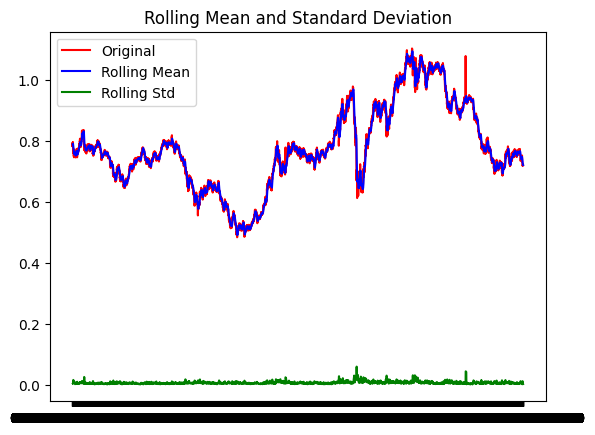

Results of Dickey-Fuller Test: 

Test Statistic                   -1.664994
p-value                           0.449233
#Lags Used                        1.000000
Number of Observations Used    7586.000000
Critical Value (1%)              -3.431212
Critical Value (5%)              -2.861921
Critical Value (10%)             -2.566973
dtype: float64


In [11]:
test_stationarity(exchange['Ex_rate'])

Test stats is greater than critical value and it lies inside, so we reject H0(i.e, Data is not stationary). To make it stationary, I used differencing technique

Differencing:
---

In [12]:
#taking with shift = 1
exchange['Exchange_diff'] = exchange['Ex_rate'] - exchange['Ex_rate'].shift(1)
exchange.head()

,Ex_rate,Exchange_diff
date,,
01-01-1990 00:00,0.7855,NaN
02-01-1990 00:00,0.7818,-0.0037
03-01-1990 00:00,0.7867,0.0049
04-01-1990 00:00,0.7860,-0.0007
05-01-1990 00:00,0.7849,-0.0011


In [13]:
#dropping first NaN column
exchange.dropna(inplace = True)
exchange

,Ex_rate,Exchange_diff
date,,
02-01-1990 00:00,0.781800,-0.003700
03-01-1990 00:00,0.786700,0.004900
04-01-1990 00:00,0.786000,-0.000700
05-01-1990 00:00,0.784900,-0.001100
06-01-1990 00:00,0.786600,0.001700
...,...,...
06-10-2010 00:00,0.718494,-0.000207
07-10-2010 00:00,0.721839,0.003345
08-10-2010 00:00,0.723197,0.001358


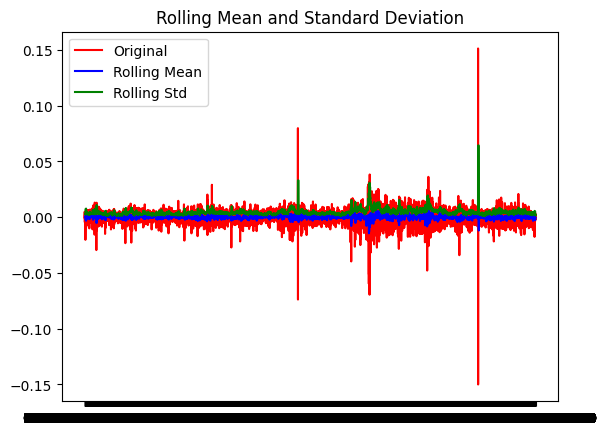

Results of Dickey-Fuller Test: 

Test Statistic                  -99.393431
p-value                           0.000000
#Lags Used                        0.000000
Number of Observations Used    7586.000000
Critical Value (1%)              -3.431212
Critical Value (5%)              -2.861921
Critical Value (10%)             -2.566973
dtype: float64


In [14]:
#again checking stationary for the differencing data
test_stationarity(exchange['Exchange_diff'])

Here we can observed that test stasts is less than critical value and it lies outside, so we fail to reject H0 here i.e, data is stationary




Explanation:
---

In Part 1, I first loaded the exchange_rate.csv dataset and correctly parsed the date column as the index. Then I checked the dataset basic information. After that, I plotted to visually understand the overall trend, ups and downs, and any sudden spikes/anomalies. To understand the components more clearly, I applied seasonal decomposition which separates the series into trend, seasonal, and residual parts. Next, I tested stationarity using Rolling Mean/Standard Deviation and the Dickey-Fuller test. Since the original data was not stationary, I applied differencing using shift(1). After differencing, we dropped the missing value created at the first row and rechecked stationarity again. Finally, the ADF test gave a very small p-value, so we rejected the null hypothesis (H0) and confirmed the differenced series is stationary, which makes it suitable for ARIMA model building.

# **`Part 2: Model Building - ARIMA`**



**1.	Parameter Selection for ARIMA: Utilize ACF and PACF plots to estimate initial parameters (p, d, q) for the ARIMA model for one or more currency time series.**


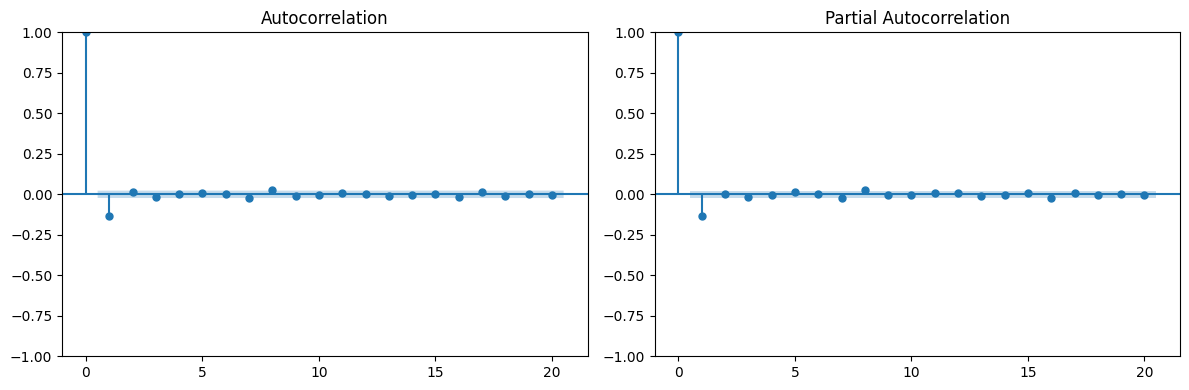

In [15]:
#plotting plots to estimate p and q values
fig, axes = plt.subplots(1,2)
fig.set_figwidth(12)
fig.set_figheight(4)
smt.graphics.plot_acf(exchange['Exchange_diff'], lags = 20, ax = axes[0])
smt.graphics.plot_pacf(exchange['Exchange_diff'], lags = 20, ax = axes[1])
plt.tight_layout()

**2.	Model Fitting: Fit the ARIMA model with the selected parameters to the preprocessed time series.**


In [16]:
#from above plot we take q=1, p=1 and also d=1
model = ARIMA(exchange['Ex_rate'], order = (1,1,1))

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


In [17]:
result = model.fit()

**3.	Diagnostics: Analyze the residuals to ensure there are no patterns that might indicate model inadequacies.**


<Axes: xlabel='date'>

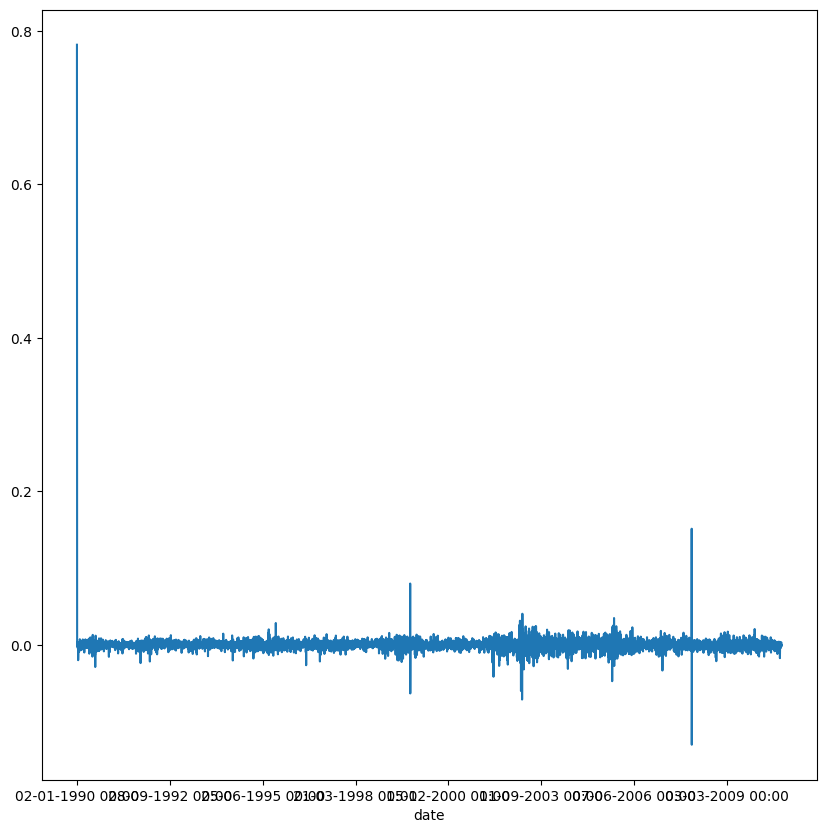

In [18]:
residuals = result.resid

plt.figure(figsize=(10,10))
residuals.plot()

**4.	Forecasting: Perform out-of-sample forecasting and visualize the predicted values against the actual values.**

In [19]:
result.predict()

,predicted_mean
date,
02-01-1990 00:00,0.000000
03-01-1990 00:00,0.781800
04-01-1990 00:00,0.786056
05-01-1990 00:00,0.786089
06-01-1990 00:00,0.785045
...,...
06-10-2010 00:00,0.718837
07-10-2010 00:00,0.718522
08-10-2010 00:00,0.721400


In [20]:
exchange['predicted'] = result.predict()

In [21]:
forecast = result.forecast(30)
forecast

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


,predicted_mean
7587,0.720826
7588,0.720826
7589,0.720826
7590,0.720826
7591,0.720826
7592,0.720826
7593,0.720826
7594,0.720826
7595,0.720826
7596,0.720826


In [22]:
#creates dates for forecast
future_dates = pd.date_range(start = exchange.index[-1], periods = 30+1, freq = 'D')[1:]
future_dates

DatetimeIndex(['2010-10-11', '2010-10-12', '2010-10-13', '2010-10-14',
               '2010-10-15', '2010-10-16', '2010-10-17', '2010-10-18',
               '2010-10-19', '2010-10-20', '2010-10-21', '2010-10-22',
               '2010-10-23', '2010-10-24', '2010-10-25', '2010-10-26',
               '2010-10-27', '2010-10-28', '2010-10-29', '2010-10-30',
               '2010-10-31', '2010-11-01', '2010-11-02', '2010-11-03',
               '2010-11-04', '2010-11-05', '2010-11-06', '2010-11-07',
               '2010-11-08', '2010-11-09'],
              dtype='datetime64[ns]', freq='D')

In [23]:
#attach future dates to forecast values
forecast_series = pd.Series(forecast.values, index = future_dates)

In [25]:
#fixes date index format
exchange.index = pd.to_datetime(exchange.index, dayfirst=True)

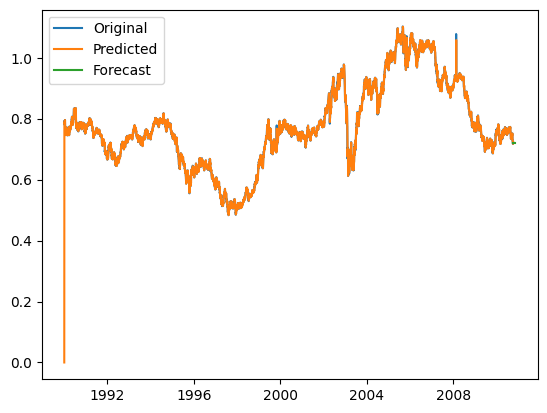

In [26]:
plt.plot(exchange['Ex_rate'], label='Original')
plt.plot(exchange['predicted'], label='Predicted')
plt.plot(forecast_series, label='Forecast')
plt.legend()

Explanation:
---

In this part, I built an ARIMA model to predict and forecast exchange rate values. First, I used ACF and PACF plots on the differenced data to choose the ARIMA parameters (p, q), and based on the plots I selected ARIMA(1,1,1). Then I trained the model using fit() and checked the residual plot. Finally, I generated predicted values for the existing data and forecasted the next 30 days, and plotted original, predicted, and forecast values together for comparison.

# **`Part 3: Evaluation and Comparison`**


**1.	Compute Error Metrics: Use metrics such as MAE, RMSE, and MAPE to evaluate the forecasts from both models.**



In [27]:
#for arima model
mae_arima = mean_absolute_error(exchange['Ex_rate'], exchange['predicted'])
rmse_arima = root_mean_squared_error(exchange['Ex_rate'], exchange['predicted'])
mape_arima = mean_absolute_percentage_error(exchange['Ex_rate'], exchange['predicted'])

In [28]:
print("ARIMA Error Metrics:")
print("MAE:", mae_arima)
print("RMSE:", rmse_arima)
print("MAPE:", mape_arima)

ARIMA Error Metrics:
MAE: 0.0037954612722953607
RMSE: 0.010794237652400467
MAPE: 0.004951465441582688


Exponential Smoothing:
---

In [31]:
#exponential smoothing model
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [32]:
exp_model = ExponentialSmoothing(exchange['Ex_rate'], trend = 'add', seasonal = 'add', seasonal_periods = 365)
exp_fit = exp_model.fit()

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/holtwinters/model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


In [33]:
exchange['exp_predicted'] = exp_fit.fittedvalues

In [34]:
#for exponential smoothing
mae_exp = mean_absolute_error(exchange['Ex_rate'], exchange['exp_predicted'])
rmse_exp = root_mean_squared_error(exchange['Ex_rate'], exchange['exp_predicted'])
mape_exp = mean_absolute_percentage_error(exchange['Ex_rate'], exchange['exp_predicted'])

In [35]:
print("Exponential Smoothing Error Metrics:")
print("MAE:", mae_exp)
print("RMSE:", rmse_exp)
print("MAPE:", mape_exp)

Exponential Smoothing Error Metrics:
MAE: 0.0037127425065621106
RMSE: 0.00591907208365484
MAPE: 0.004851532747567978


I evaluated the performance of both ARIMA and Exponential Smoothing models using three standard metrics: MAE, RMSE, and MAPE. These values tell us how close the model predictions are to the actual exchange rate values, and since all the error values are very small, it means both models are performing well on this dataset. We used the Exponential Smoothing model as the second model because the objective clearly mentions ARIMA and Exponential Smoothing and Exponential Smoothing is very effective for time series data where trend/seasonality patterns exist. Based on the results, Exponential Smoothing gave slightly lower errors compared to ARIMA, so it performed a little better in forecasting accuracy for this dataset.

**2.	Model Comparison: Discuss the performance, advantages, and limitations of each model based on the observed results and error metrics.**


Based on the MAE, RMSE and MAPE values, both ARIMA and Exponential Smoothing performed really well because the error values are very low, which means the predicted exchange rates are very close to the actual values. ARIMA works better when the data depends on past values and patterns like autocorrelation, and it is strong for short-term forecasting after making the series stationary using differencing. Exponential Smoothing is useful because it focuses on smoothing the trend and seasonal components, so it can handle level + trend changes smoothly. In our results, Exponential Smoothing gave slightly better (lower) error values than ARIMA, meaning it fitted the exchange rate series more accurately. However, ARIMA can sometimes struggle if the pattern changes suddenly, and Exponential Smoothing may not work perfectly when the data has irregular fluctuations or unexpected shocks.

**3.	Conclusion: Summarize the findings and provide insights on which model(s) yielded the best performance for forecasting exchange rates in this dataset.**

From the overall evaluation, both models produced good forecasts with very small error values, showing that the dataset is predictable to some extent. But when we compare the error metrics, Exponential Smoothing gives slightly lower MAE, RMSE and MAPE compared to ARIMA, so it performed better for this dataset. Therefore, for forecasting exchange rates in this dataset, Exponential Smoothing can be considered the best model among the two. Still, ARIMA is also a strong model and can give good results, especially for short-term forecasting and when the series is stationary.